# 2. NumPy arrays and simulation

Start with arrays of scores: create them, select values, calculate summaries and work with rows
and columns. Then use the same operations for returns, risk and simulated investment outcomes.
An **import** makes a library available; `as np` gives NumPy a short local name.
`FloatArray` below is a reusable type-hint name for a NumPy array of 64-bit floats.

In [1]:
from __future__ import annotations

from collections.abc import Callable
from functools import partial
from math import isfinite, sqrt
from statistics import median
from timeit import repeat

import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray

type FloatArray = NDArray[np.float64]

plt.rcParams.update(
    {"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False}
)

## Creating and inspecting arrays

A NumPy array holds values of one **dtype**, such as 64-bit floats.
`shape` gives the lengths of its dimensions; `size` counts its values.
`FloatArray` describes the dtype in annotations, but does not specify an array's shape.

In [2]:
scores: FloatArray = np.array([60.0, 75.0, 90.0, 45.0], dtype=np.float64)
print("Scores:", scores)
print("Shape, dimensions, size:", scores.shape, scores.ndim, scores.size)
print("dtype and data bytes:", scores.dtype, scores.nbytes)
print("Regular sequence:", np.arange(0.0, 10.0, 2.0))
print("Five evenly spaced values:", np.linspace(0.0, 1.0, 5))
print("Zeros:", np.zeros(3), "Ones:", np.ones(3))
print("A repeated value:", np.full(3, 0.5))

Scores: [60. 75. 90. 45.]
Shape, dimensions, size: (4,) 1 4
dtype and data bytes: float64 32
Regular sequence: [0. 2. 4. 6. 8.]
Five evenly spaced values: [0.   0.25 0.5  0.75 1.  ]
Zeros: [0. 0. 0.] Ones: [1. 1. 1.]
A repeated value: [0.5 0.5 0.5]


## Arithmetic, slices and masks

Array arithmetic acts on each value. A comparison produces a Boolean array called a **mask**;
using it as an index keeps the values where the mask is true. `np.where` chooses between two
results. `np.clip` limits values to a range.
A Python list stores references to objects; a numerical array stores values in a compact typed buffer.
NumPy's numerical loops run in compiled code, avoiding a Python operation for every element.

In [3]:
print("First two:", scores[:2], "Every second value:", scores[::2])
print("Five-point bonus:", scores + 5.0)
print("Bonus capped at 100:", np.clip(scores + 20.0, 0.0, 100.0))
print("Passing mask:", scores >= 60.0)
print("Passing scores:", scores[scores >= 60.0])
print("Labels:", np.where(scores >= 60.0, "pass", "retry"))
print("Joined arrays:", np.concatenate([scores, np.array([80.0])]))
print("List * 2:", scores.tolist() * 2)
print("Array * 2:", scores * 2.0)

First two: [60. 75.] Every second value: [60. 90.]
Five-point bonus: [65. 80. 95. 50.]
Bonus capped at 100: [ 80.  95. 100.  65.]
Passing mask: [ True  True  True False]
Passing scores: [60. 75. 90.]
Labels: ['pass' 'pass' 'pass' 'retry']
Joined arrays: [60. 75. 90. 45. 80.]
List * 2: [60.0, 75.0, 90.0, 45.0, 60.0, 75.0, 90.0, 45.0]
Array * 2: [120. 150. 180.  90.]


## Summaries and cumulative calculations

Reductions such as `mean` produce one result from many values. `ddof=1` requests the sample
standard deviation. The 75th percentile has about 75% of values at or below it.
`cumsum` and `cumprod` keep a running sum or product instead of returning just the final result.

In [4]:
print("Sum, mean, min, max:", scores.sum(), scores.mean(), scores.min(), scores.max())
print("Sample standard deviation:", scores.std(ddof=1))
print("75th percentile:", np.quantile(scores, 0.75))
print("Index of highest score:", int(scores.argmax()))
print("Running total:", np.cumsum([2.0, 3.0, 4.0]))
print("Running product:", np.cumprod([2.0, 3.0, 4.0]))
print("Best score so far:", np.maximum.accumulate(scores))
print("Capped at 70:", np.minimum(scores, 70.0))
print("Squares and square roots:", np.square(scores), np.sqrt(scores))

Sum, mean, min, max: 270.0 67.5 45.0 90.0
Sample standard deviation: 19.364916731037084
75th percentile: 78.75
Index of highest score: 2
Running total: [2. 5. 9.]
Running product: [ 2.  6. 24.]
Best score so far: [60. 75. 90. 90.]
Capped at 70: [60. 70. 70. 45.]
Squares and square roots: [3600. 5625. 8100. 2025.] [7.74596669 8.66025404 9.48683298 6.70820393]


## Rows, columns and broadcasting

This table has two students (rows) and three quizzes (columns).
`axis=0` reduces down the rows, giving one result per quiz.
`axis=1` reduces across columns, giving one result per student.
**Broadcasting** applies a scalar or a compatible array across another array.

In [5]:
quiz_scores: FloatArray = np.array([[60.0, 70.0, 80.0], [80.0, 90.0, 100.0]])
quiz_bonus: FloatArray = np.array([1.0, 2.0, 3.0])
quiz_weights: FloatArray = np.array([0.2, 0.3, 0.5])

print("Shape:", quiz_scores.shape)
print("First student:", quiz_scores[0], "First quiz:", quiz_scores[:, 0])
print("Mean per quiz:", quiz_scores.mean(axis=0))
print("Mean per student:", quiz_scores.mean(axis=1))
print("Bonus per quiz:\n", quiz_scores + quiz_bonus)
print("Weighted score per student:", quiz_scores @ quiz_weights)
print("Reshaped into one row:", quiz_scores.reshape(1, 6))
print("Stacked score rows:\n", np.vstack([scores, scores + 5.0]))
print("Sample covariance between quizzes:\n", np.cov(quiz_scores, rowvar=False, ddof=1))
np.testing.assert_allclose(quiz_scores.mean(axis=1), [70.0, 90.0])
np.testing.assert_allclose(quiz_scores @ quiz_weights, [73.0, 93.0])

Shape: (2, 3)
First student: [60. 70. 80.] First quiz: [60. 80.]
Mean per quiz: [70. 80. 90.]
Mean per student: [70. 90.]
Bonus per quiz:
 [[ 61.  72.  83.]
 [ 81.  92. 103.]]
Weighted score per student: [73. 93.]
Reshaped into one row: [[ 60.  70.  80.  80.  90. 100.]]
Stacked score rows:
 [[60. 75. 90. 45.]
 [65. 80. 95. 50.]]
Sample covariance between quizzes:
 [[200. 200. 200.]
 [200. 200. 200.]
 [200. 200. 200.]]


`@` multiplies and sums matching entries: the first weighted score is
`60 * 0.2 + 70 * 0.3 + 80 * 0.5 = 73`.
`cov` measures how columns vary together. `rowvar=False` treats columns as variables;
diagonal entries are their variances. With only two students this is just a calculation example.

## Random numbers

A random-number generator produces samples. A fixed **seed** makes a run reproducible.
A normal distribution has a centre (`loc`) and a standard deviation (`scale`).

In [6]:
score_rng = np.random.default_rng(42)
random_scores: FloatArray = score_rng.normal(loc=70.0, scale=10.0, size=(3, 4))
print("Invented scores:\n", random_scores.round(1))
print("Random choices:", score_rng.choice(["Python", "Statistics"], size=5))
np.testing.assert_array_equal(
    random_scores, np.random.default_rng(42).normal(70.0, 10.0, size=(3, 4))
)

Invented scores:
 [[73.  59.6 77.5 79.4]
 [50.5 57.  71.3 66.8]
 [69.8 61.5 78.8 77.8]]
Random choices: ['Statistics' 'Statistics' 'Python' 'Statistics' 'Statistics']


**Exercise:** select the scores at or above 75 and calculate their mean.
Try it before running the solution.

In [7]:
selected_scores: FloatArray = scores[scores >= 75.0]
print("Selected:", selected_scores, "Mean:", selected_scores.mean())
np.testing.assert_allclose(selected_scores.mean(), 82.5)

Selected: [75. 90.] Mean: 82.5


## Using arrays for returns

A return is `new_price / old_price - 1`, as in notebook 1.
The slices below pair adjacent prices. Four prices produce three returns.
Multiply the growth factors `1 + return` to compound wealth.

In [8]:
prices: list[float] = [100.0, 102.0, 101.0, 104.0]
price_array: FloatArray = np.array(prices, dtype=np.float64)
print("Shape:", price_array.shape, "dtype:", price_array.dtype, "data bytes:", price_array.nbytes)

Shape: (4,) dtype: float64 data bytes: 32


**Vectorisation** asks a library to perform a whole numerical operation.
The division and subtraction below operate on corresponding values in the two slices.

In [9]:
returns: FloatArray = price_array[1:] / price_array[:-1] - 1.0
wealth: FloatArray = 1_000.0 * np.cumprod(1.0 + returns)
print("Returns:", returns)
print("Wealth after each return:", wealth)
print("Mean daily return:", float(returns.mean()))
print("Sample daily volatility:", float(returns.std(ddof=1)))
assert returns.shape == (3,)
np.testing.assert_allclose(wealth[-1], 1_040.0)

Returns: [ 0.02       -0.00980392  0.02970297]
Wealth after each return: [1020. 1010. 1040.]
Mean daily return: 0.013299682909467444
Sample daily volatility: 0.02058808667789321


`price_array[1:]` and `price_array[:-1]` pair today's and yesterday's prices.
`cumprod` compounds growth factors. **Volatility** is a standard deviation: a measure
of variation, rather than a forecast of the worst possible loss. `ddof=1` uses the sample estimate.

### Optional: downside deviation and timings

**Daily downside deviation with target zero** measures the size of negative returns:
square negative returns, give non-negative returns zero, average across **all days**, then take a square root.
This is not the standard deviation of just the losing days.

In [10]:
def downside_python(values: list[float]) -> float:
    if not values or not all(isfinite(value) for value in values):
        raise ValueError("Expected non-empty, finite returns.")
    total: float = 0.0
    for value in values:
        if value < 0.0:
            total += value * value
    return sqrt(total / len(values))


def downside_numpy(values: FloatArray) -> float:
    if values.ndim != 1 or values.size == 0 or not np.isfinite(values).all():
        raise ValueError("Expected a non-empty, finite, one-dimensional array.")
    negative: FloatArray = np.minimum(values, 0.0)
    return float(np.sqrt(np.mean(negative**2)))


example: FloatArray = np.array([-0.02, 0.01, -0.01, 0.0])
expected: float = sqrt((0.02**2 + 0.01**2) / 4.0)
np.testing.assert_allclose(downside_python(example.tolist()), expected)
np.testing.assert_allclose(downside_numpy(example), expected)
np.testing.assert_allclose(downside_numpy(np.zeros(4)), 0.0)
print(f"Example daily downside deviation: {expected:.2%}")

Example daily downside deviation: 1.12%


### Optional: comparing Python and NumPy

Which version should be faster for ten values? What about 250,000?
We build inputs before timing, use the same values and result definition, and check agreement.
`partial` supplies a function's input now so that the timer can call it repeatedly.
We show the median of five batches of three calls. This includes each implementation's
validation and arithmetic, but excludes generating data and converting the list.

n=     10 | Python 0.0005 ms | NumPy 0.0024 ms
n=  1,000 | Python 0.0259 ms | NumPy 0.0102 ms
n=250,000 | Python 6.6365 ms | NumPy 0.1461 ms


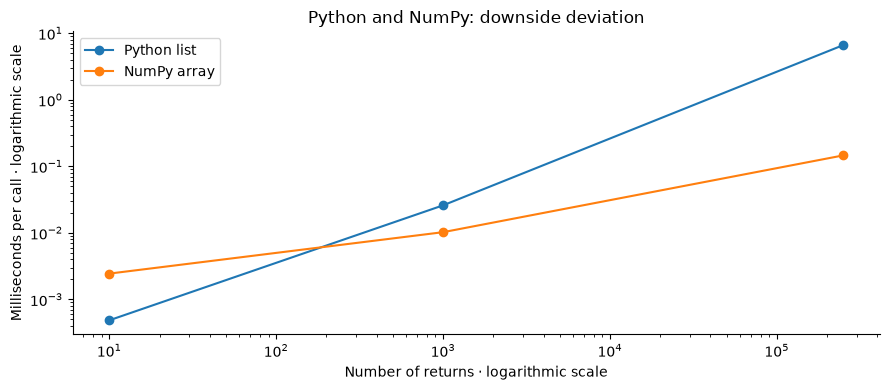

In [11]:
sizes: list[int] = [10, 1_000, 250_000]
python_ms: list[float] = []
numpy_ms: list[float] = []
benchmark_rng = np.random.default_rng(42)

for size in sizes:
    array: FloatArray = benchmark_rng.normal(0.0, 0.01, size)
    as_list: list[float] = array.tolist()
    np.testing.assert_allclose(downside_python(as_list), downside_numpy(array), rtol=1e-12)
    operations: list[tuple[str, Callable[[], float]]] = [
        ("Python", partial(downside_python, as_list)),
        ("NumPy", partial(downside_numpy, array)),
    ]
    measured: dict[str, float] = {}
    for label, operation in operations:
        operation()
        measured[label] = median(repeat(operation, number=3, repeat=5)) / 3.0 * 1_000.0
    python_ms.append(measured["Python"])
    numpy_ms.append(measured["NumPy"])
    print(f"n={size:>7,} | Python {measured['Python']:.4f} ms | NumPy {measured['NumPy']:.4f} ms")

fig, ax = plt.subplots()
ax.loglog(sizes, python_ms, "o-", label="Python list")
ax.loglog(sizes, numpy_ms, "o-", label="NumPy array")
ax.set(
    xlabel="Number of returns · logarithmic scale",
    ylabel="Milliseconds per call · logarithmic scale",
    title="Python and NumPy: downside deviation",
)
ax.legend()
plt.tight_layout()
plt.show()

A small array may lose to setup overhead. Large arrays often benefit from compiled loops
and contiguous numeric storage. Temporary arrays and list-to-array conversion also cost time.
`np.vectorize` is a convenience wrapper around Python calls, not this kind of speed-up.
The result depends on array size, data layout and hardware.

## Simulating returns

A **Monte Carlo simulation** samples possible outcomes from a model.
Start with a deliberately simple model: each day is independently either +1% or −1%,
with equal probability. Each column will be one possible sequence of days.
This is an exercise in sampling and compounding, rather than a realistic market model.

In [12]:
rng = np.random.default_rng(2026)
trading_days: int = 20
paths: int = 2_000
daily_move: float = 0.01
initial_capital: float = 1_000.0
if not 0.0 < daily_move < 1.0:
    raise ValueError("The daily move must be between zero and one.")

simulated_returns: FloatArray = rng.choice(
    np.array([-daily_move, daily_move]), size=(trading_days, paths)
)
path_values: FloatArray = initial_capital * np.vstack(
    [np.ones(paths), np.cumprod(1.0 + simulated_returns, axis=0)]
)
terminal_values: FloatArray = path_values[-1]
losses: FloatArray = initial_capital - terminal_values
loss_probability: float = float(np.mean(terminal_values < initial_capital))
loss_percentile_95: float = float(np.quantile(losses, 0.95))

print("Rows = dates, columns = scenarios:", path_values.shape)
print(f"Simulated probability of losing money: {loss_probability:.1%}")
print(f"Simulated 95th percentile {trading_days}-day loss: £{loss_percentile_95:.2f}")
assert path_values.shape == (trading_days + 1, paths)
assert np.isfinite(path_values).all() and (path_values > 0.0).all()

Rows = dates, columns = scenarios: (21, 2000)
Simulated probability of losing money: 59.0%
Simulated 95th percentile 20-day loss: £77.81


`axis=0` works **down the dates**, separately for each scenario.
A scalar such as `initial_capital` is **broadcast** across an array without writing a Python loop.
Shape still needs attention even when the dtype is annotated.

The loss percentile is an empirical **Value at Risk** estimate under this model:
roughly 5% of simulated losses exceed it. Larger losses are still possible.
This estimate depends on the model's assumptions.

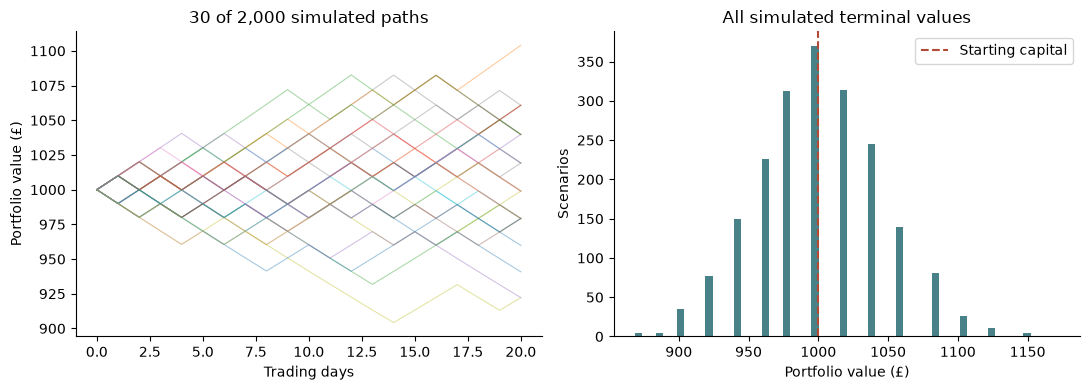

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(path_values[:, :30], alpha=0.4, linewidth=0.8)
axes[0].set(
    title="30 of 2,000 simulated paths", xlabel="Trading days", ylabel="Portfolio value (£)"
)
axes[1].hist(terminal_values, bins=60, color="#286b73", alpha=0.85)
axes[1].axvline(initial_capital, color="#b34a36", linestyle="--", label="Starting capital")
axes[1].set(title="All simulated terminal values", xlabel="Portfolio value (£)", ylabel="Scenarios")
axes[1].legend()
plt.tight_layout()
plt.show()

**Exercise:** change the daily move from `0.01` to `0.02`, then rerun
the simulation and plot cells. Predict what happens to the spread and the downside first.
The fixed seed holds the underlying random draws constant; it is not a fitted parameter.
Restore `0.01` afterwards.

Further reading: [NumPy arrays and compiled operations](https://numpy.org/doc/stable/user/whatisnumpy.html).